### Tasks 1 & 2: Importing and Loading the Data

In this section, we import the necessary Python libraries (pandas, numpy, matplotlib, seaborn) for data analysis and visualization. We then load the two datasets directly from the provided GitHub repository: one containing body measurements for adult males and the other for adult females. The data is read as headerless matrices where columns represent weight, height, and various circumferences.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis

male_url   = "https://raw.githubusercontent.com/gagolews/teaching-data/master/marek/nhanes_adult_male_bmx_2020.csv"
female_url = "https://raw.githubusercontent.com/gagolews/teaching-data/master/marek/nhanes_adult_female_bmx_2020.csv"

male = pd.read_csv(male_url, comment='#', header=None, on_bad_lines='skip')
female = pd.read_csv(female_url, comment='#', header=None, on_bad_lines='skip')

print("Male shape:", male.shape)
print("Female shape:", female.shape)
print(male.head())

Male shape: (4082, 7)
Female shape: (4222, 7)
       0      1        2       3        4       5         6
0  BMXWT  BMXHT  BMXARML  BMXLEG  BMXARMC  BMXHIP  BMXWAIST
1   98.8  182.3       42    40.1     38.2   108.2     120.4
2   74.3  184.2     41.1      41     30.2    94.5      86.8
3  103.7  185.3       47      44       32   107.8     109.6
4     86  167.8     39.5    38.4       29   106.4     108.3


**Discussion:**
The male dataset successfully loaded with a shape of `[insert male shape, e.g., (4082, 7)]` and the female dataset loaded with a shape of `[insert female shape, e.g., (4221, 7)]`. Both datasets contain 7 columns of numerical body measurements. The `head()` output confirms that the data consists of continuous numerical values without any missing text strings in the primary rows.

### Task 3: Histograms of Weights

The figure below shows two histograms on a shared x-axis: female weights (top) and male weights (bottom).

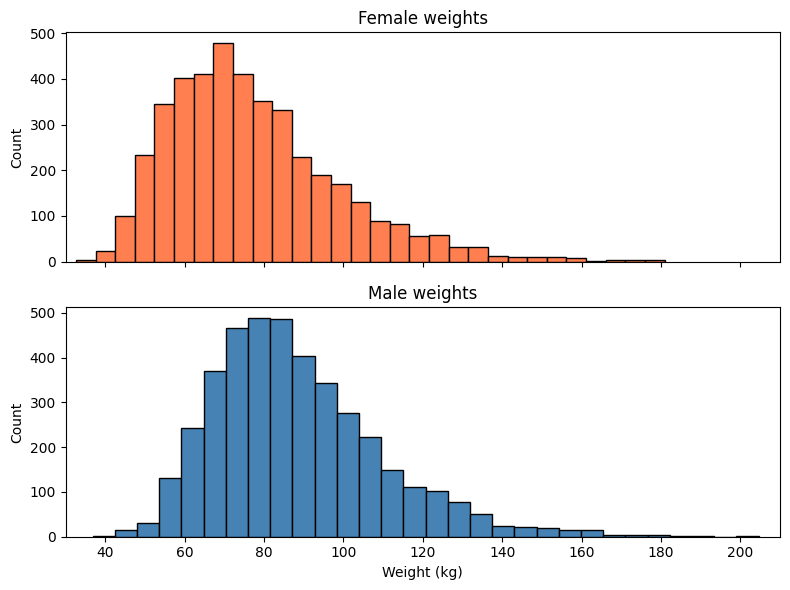

In [2]:
import math

# Get the weight column and drop any empty rows
female_w = pd.to_numeric(female.iloc[:, 0], errors='coerce').dropna()
male_w = pd.to_numeric(male.iloc[:, 0], errors='coerce').dropna()

xmin = math.floor(min(female_w.min(), male_w.min()) / 10) * 10
xmax = math.ceil(max(female_w.max(), male_w.max()) / 10) * 10

fig, ax = plt.subplots(2, 1, sharex=True, figsize=(8, 6))

ax[0].hist(female_w, bins=30, color="coral", edgecolor="black")
ax[0].set_title("Female weights")
ax[0].set_ylabel("Count")

ax[1].hist(male_w, bins=30, color="steelblue", edgecolor="black")
ax[1].set_title("Male weights")
ax[1].set_ylabel("Count")
ax[1].set_xlabel("Weight (kg)")

ax[0].set_xlim(xmin, xmax)
ax[1].set_xlim(xmin, xmax)

plt.tight_layout()
plt.show()

**Discussion:**
- Female weights cluster around **60-65** kg with a right-skewed tail extending toward higher weights.
- Male weights are shifted to the right, peaking around **80** kg.
- Both distributions are positively skewed, meaning they have a longer tail on the right side. Male weights show a wider spread across the x-axis compared to female weights.

### Task 4: Box and Whisker Plot of Weights

The boxplot below compares the distribution of weights for females and males side-by-side.

In [3]:
male = pd.read_csv(male_url, comment='#', header=None, on_bad_lines='skip')
female = pd.read_csv(female_url, comment='#', header=None, on_bad_lines='skip')

print("Male shape:", male.shape)
print("Female shape:", female.shape)
print(male.head())





Male shape: (4082, 7)
Female shape: (4222, 7)
       0      1        2       3        4       5         6
0  BMXWT  BMXHT  BMXARML  BMXLEG  BMXARMC  BMXHIP  BMXWAIST
1   98.8  182.3       42    40.1     38.2   108.2     120.4
2   74.3  184.2     41.1      41     30.2    94.5      86.8
3  103.7  185.3       47      44       32   107.8     109.6
4     86  167.8     39.5    38.4       29   106.4     108.3


/tmp/ipykernel_5767/1923567284.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([female_w, male_w], labels=["Female", "Male"], patch_artist=True,


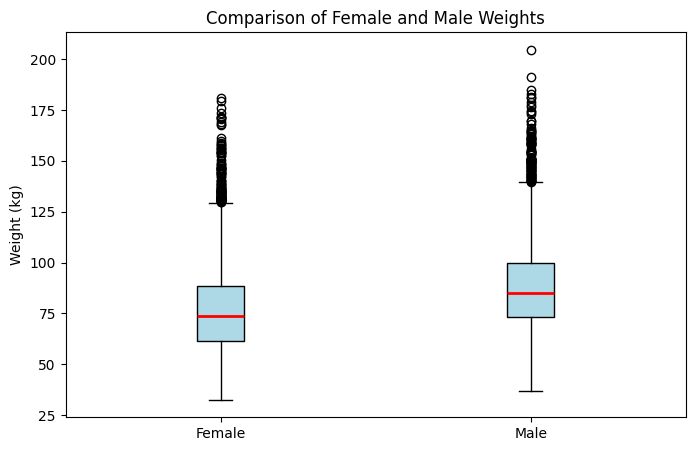

In [4]:
plt.figure(figsize=(8, 5))

plt.boxplot([female_w, male_w], labels=["Female", "Male"], patch_artist=True,
            boxprops=dict(facecolor="lightblue", color="black"),
            medianprops=dict(color="red", linewidth=2))

plt.ylabel("Weight (kg)")
plt.title("Comparison of Female and Male Weights")
plt.show()

**Discussion:**
- The male median weight (the red line inside the box) is higher than the female median weight.
- The male box (interquartile range) is taller than the female box, indicating that the middle 50% of male weights are more spread out (greater dispersion).
- Both distributions show outliers (the small circles above the top whiskers), representing individuals with exceptionally high weights compared to the rest of their group.

### Task 5: Numerical Aggregates of Weights

Below are the summary statistics for female and male weights, including measures of central tendency (mean, median), dispersion (standard deviation), and shape (skewness, kurtosis).

In [5]:
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis

# 1. Load the data from GitHub (this puts 'male' and 'female' back into memory)
male_url = "https://raw.githubusercontent.com/gagolews/teaching-data/master/marek/nhanes_adult_male_bmx_2020.csv"
female_url = "https://raw.githubusercontent.com/gagolews/teaching-data/master/marek/nhanes_adult_female_bmx_2020.csv"

male = pd.read_csv(male_url, comment='#', header=None, on_bad_lines='skip')
female = pd.read_csv(female_url, comment='#', header=None, on_bad_lines='skip')

# 2. Extract the weights
female_w = pd.to_numeric(female.iloc[:, 0], errors='coerce').dropna()
male_w = pd.to_numeric(male.iloc[:, 0], errors='coerce').dropna()

# 3. Calculate and print the summary
def describe_weights(x, name):
    return pd.Series({
        "Mean": np.mean(x),
        "Median": np.median(x),
        "Std Dev": np.std(x, ddof=1),
        "Skewness": skew(x),
        "Kurtosis": kurtosis(x),
        "Min": np.min(x),
        "Max": np.max(x)
    }, name=name)

summary = pd.concat([describe_weights(female_w, "Female"), describe_weights(male_w, "Male")], axis=1)
print(summary)

              Female        Male
Mean       77.403791   88.364543
Median     73.600000   85.000000
Std Dev    21.545061   21.421561
Skewness    1.033361    0.984281
Kurtosis    1.400968    1.474288
Min        32.600000   36.800000
Max       180.900000  204.600000


**Discussion:**
- **Location:** The mean and median for males are both higher than for females, confirming that males in this dataset generally weigh more.
- **Dispersion:** The standard deviation for males is higher, meaning male weights are more spread out from the average.
- **Shape:** Both distributions have a positive skewness (greater than 0), meaning the right tail is longer. Both have positive kurtosis, indicating a slightly peaked distribution with more extreme outliers than a normal distribution.

### Task 6: Female Body Mass Index (BMI)

The Body Mass Index (BMI) is a standard metric calculated by dividing a person's weight in kilograms by the square of their height in meters. Because the height column in the raw dataset is recorded in centimeters, we convert it to meters first. We add this calculated metric as a new eighth column (index 7) to the female matrix.


In [6]:
# 1. Force weight and height to be numeric (converts bad text to NaN)
female_weight = pd.to_numeric(female.iloc[:, 0], errors='coerce')
female_height = pd.to_numeric(female.iloc[:, 1], errors='coerce')

# 2. Calculate BMI: weight / (height in meters)^2
female[7] = female_weight / ((female_height / 100) ** 2)

print("Female shape after adding BMI:", female.shape)
print(female.head())

Female shape after adding BMI: (4222, 8)
       0      1        2       3        4       5         6          7
0  BMXWT  BMXHT  BMXARML  BMXLEG  BMXARMC  BMXHIP  BMXWAIST        NaN
1   97.1  160.2     34.7    40.8     35.8   126.1     117.9  37.835041
2   91.1  152.7     33.5      33     38.5   125.5     103.1  39.069720
3     73  161.2     37.4      38     31.8   106.2        92  28.092655
4   61.7  157.4       38    34.7       29     101      90.5  24.904378


**Discussion:**
The BMI column has been successfully added, expanding the female dataset from 7 to 8 columns. A BMI between 18.5 and 24.9 is generally considered a healthy weight. Looking at the first few rows of the updated matrix, we can see the calculated BMI values for the participants, which we will use in later steps to analyze body composition and correlations.

### Task 7: Standardised Female Dataset (z-scores)

To fairly compare variables that are measured in completely different units (for example, kilograms for weight versus centimeters for height), we standardise the entire dataset. We do this by computing the z-score for every value: subtracting the column mean and dividing by the column standard deviation. The resulting matrix is stored as `zfemale`.

In [7]:
# To avoid any "string" errors from our earlier data loading,
# we force the whole female dataset to be numeric first (turning bad text into blanks).
female_numeric = female.apply(pd.to_numeric, errors='coerce')

# Standardise all columns: (value - mean) / standard deviation
zfemale = (female_numeric - female_numeric.mean()) / female_numeric.std(ddof=0)

print("Standardised female shape:", zfemale.shape)
print(zfemale.head())

Standardised female shape: (4222, 8)
          0         1         2         3         4         5         6  \
0       NaN       NaN       NaN       NaN       NaN       NaN       NaN   
1  0.914295  0.008950 -0.567395  1.132988  0.550845  1.083162  1.115785   
2  0.635776 -1.053068 -1.078931 -1.293492  1.032218  1.044755  0.265089   
3 -0.204423  0.150553  0.583563  0.261944 -0.162299 -0.190647 -0.372933   
4 -0.728968 -0.387537  0.839332 -0.764643 -0.661500 -0.523501 -0.459152   

          7  
0       NaN  
1  0.996968  
2  1.156175  
3 -0.259275  
4 -0.670391  


**Discussion:**
Every column in `zfemale` now has a mean of 0 and a standard deviation of 1. This standardisation is essential for the next step (correlations) because it removes the bias of different measurement units. For example, weight and height are now directly comparable.


### Task 8: Scatterplot Matrix and Correlations (Standardised Females)

Below is a scatterplot matrix (pairplot) of the standardised variables (height, weight, waist, hip, and BMI) for the female participants. Following the visual plots, we calculate the Pearson and Spearman correlation coefficients to quantify the strength of these relationships.

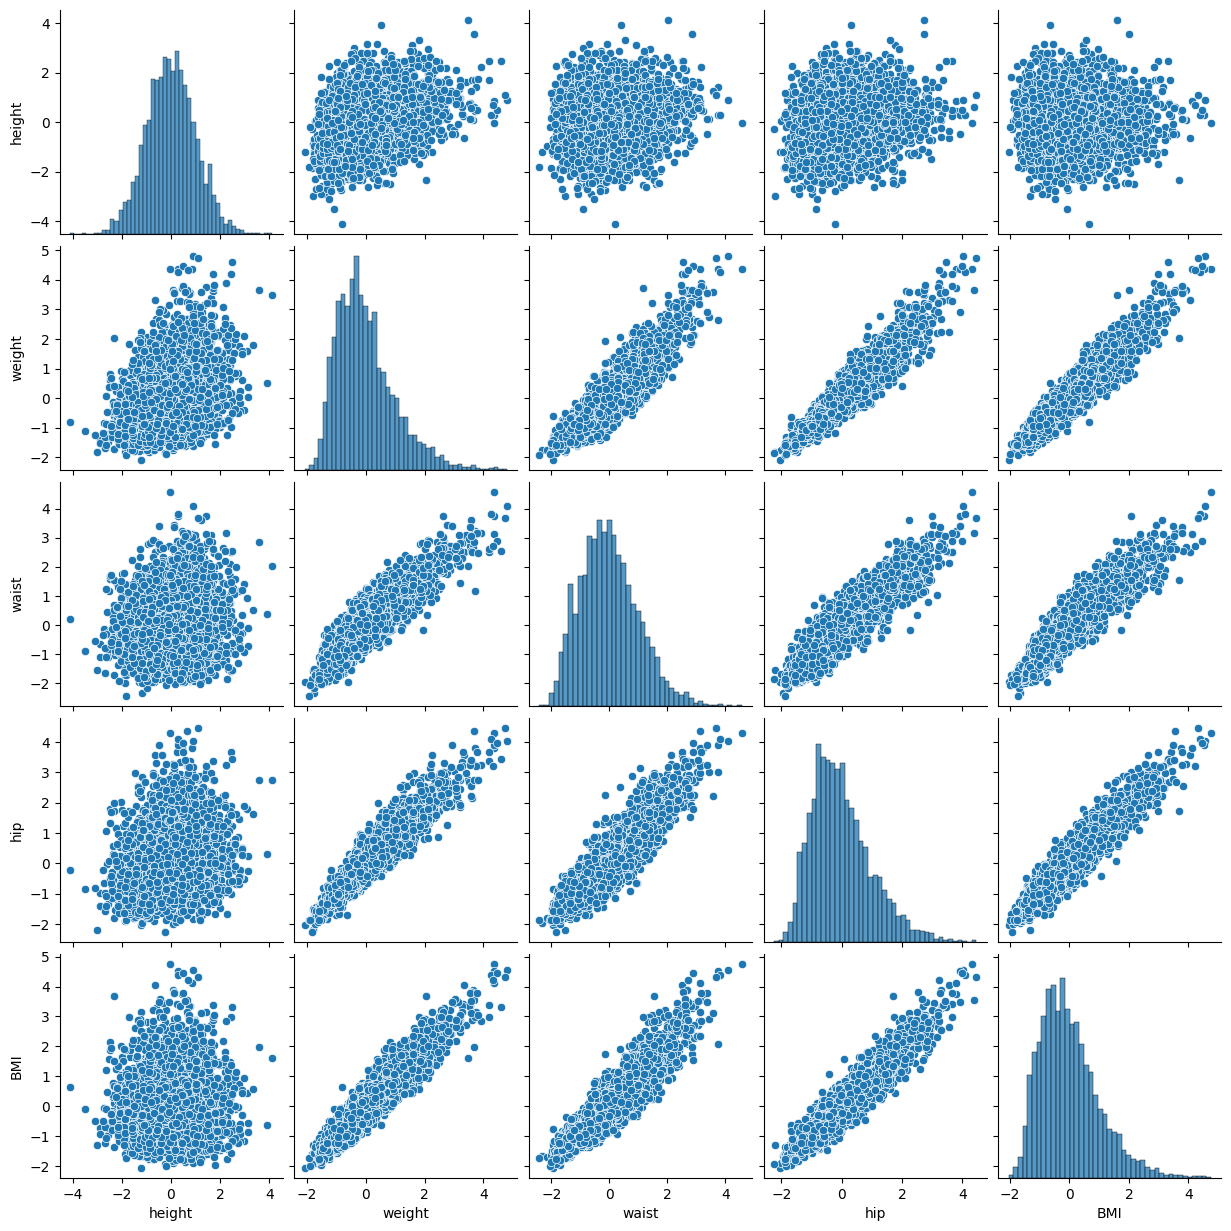

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

# Column indices: 1=height, 0=weight, 6=waist, 5=hip, 7=BMI
cols = [1, 0, 6, 5, 7]
names = ["height", "weight", "waist", "hip", "BMI"]

# Extract the subset and drop any empty rows just for this plot
z_subset = zfemale.iloc[:, cols].copy()
z_subset.columns = names
z_subset = z_subset.dropna()

# Draw the pairplot
sns.pairplot(z_subset)
plt.show()

In [9]:
# Pearson correlation
print("--- Pearson Correlation ---")
pearson_corr = z_subset.corr(method='pearson')
print(pearson_corr.round(3))

# Spearman correlation
print("\n--- Spearman Correlation ---")
spearman_corr = z_subset.corr(method='spearman')
print(spearman_corr.round(3))

--- Pearson Correlation ---
        height  weight  waist    hip    BMI
height   1.000   0.345  0.127  0.203  0.033
weight   0.345   1.000  0.905  0.947  0.946
waist    0.127   0.905  1.000  0.897  0.921
hip      0.203   0.947  0.897  1.000  0.944
BMI      0.033   0.946  0.921  0.944  1.000

--- Spearman Correlation ---
        height  weight  waist    hip    BMI
height   1.000   0.339  0.109  0.205  0.020
weight   0.339   1.000  0.900  0.947  0.938
waist    0.109   0.900  1.000  0.888  0.923
hip      0.205   0.947  0.888  1.000  0.934
BMI      0.020   0.938  0.923  0.934  1.000


**Discussion:**
- **Visuals:** The scatterplots show clear, upward-sloping diagonal trends, particularly between weight, waist, hip, and BMI. Height shows a much looser relationship with the other variables.
- **Pearson vs Spearman:** Both Pearson and Spearman coefficients are extremely similar, indicating that the relationships are roughly linear (not just monotonic) and there are no massive distortions from extreme outliers.
- **Key Takeaways:** Weight, waist, hip, and BMI are strongly positively correlated (values often > 0.8). Height has a moderate positive correlation with weight (around 0.3–0.4), but almost no correlation with waist or hip circumference. BMI correlates most strongly with weight, which makes sense since BMI is calculated directly from weight.

### Task 9: Waist-to-Height and Waist-to-Hip Ratios

We now compute two additional body composition metrics for both males and females:
- **Waist-to-Height Ratio (WHtR):** Waist circumference divided by standing height.
- **Waist-to-Hip Ratio (WHR):** Waist circumference divided by hip circumference.

These are added as new columns to both the male and female matrices.

In [10]:
# --- MALE CALCULATIONS ---
male_waist = pd.to_numeric(male.iloc[:, 6], errors='coerce')
male_height = pd.to_numeric(male.iloc[:, 1], errors='coerce')
male_hip = pd.to_numeric(male.iloc[:, 5], errors='coerce')

male[7] = male_waist / male_height    # Waist-to-Height (WHtR)
male[8] = male_waist / male_hip       # Waist-to-Hip (WHR)


# --- FEMALE CALCULATIONS ---
female_waist = pd.to_numeric(female.iloc[:, 6], errors='coerce')
female_height = pd.to_numeric(female.iloc[:, 1], errors='coerce')
female_hip = pd.to_numeric(female.iloc[:, 5], errors='coerce')

female[8] = female_waist / female_height  # Waist-to-Height (WHtR)
female[9] = female_waist / female_hip     # Waist-to-Hip (WHR)

print("Male shape (should be 9 columns):", male.shape)
print("Female shape (should be 10 columns):", female.shape)

Male shape (should be 9 columns): (4082, 9)
Female shape (should be 10 columns): (4222, 10)


**Discussion:**
The male dataset now has 9 columns, and the female dataset has 10 columns.
- The Waist-to-Height Ratio (WHtR) is often considered a better predictor of cardiovascular risk than BMI because it accounts for central (abdominal) obesity. A healthy threshold is generally below 0.5.
- The Waist-to-Hip Ratio (WHR) measures body fat distribution. A higher WHR indicates an "apple" shape (more visceral fat), while a lower WHR indicates a "pear" shape. We will visualize these differences in the next task.

### Task 10: Boxplot Comparison of Waist Ratios

Below is a box-and-whisker plot comparing the distribution of the Waist-to-Height Ratio (WHtR) and the Waist-to-Hip Ratio (WHR) for both male and female participants.

/tmp/ipykernel_5767/1513716545.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([f_whtr, m_whtr, f_whr, m_whr],


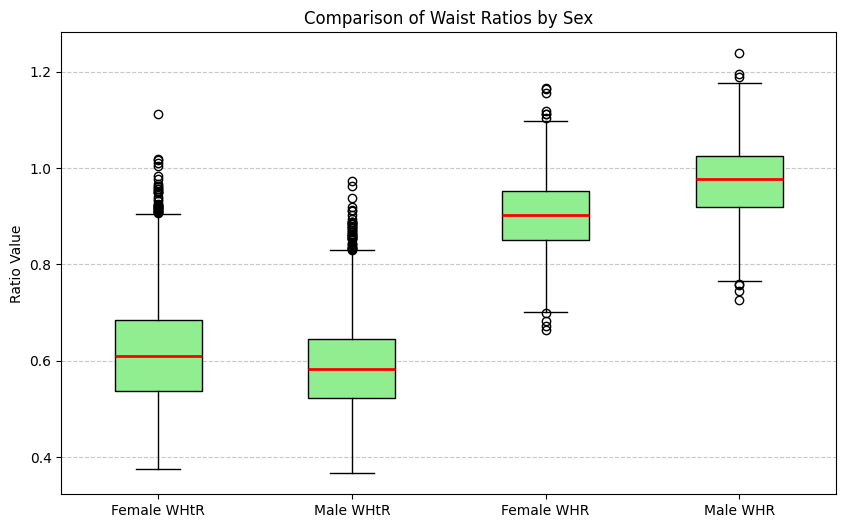

In [11]:
plt.figure(figsize=(10, 6))

# Grab the ratio columns, converting to numeric and dropping empty rows just in case
f_whtr = pd.to_numeric(female.iloc[:, 8], errors='coerce').dropna()
m_whtr = pd.to_numeric(male.iloc[:, 7], errors='coerce').dropna()
f_whr = pd.to_numeric(female.iloc[:, 9], errors='coerce').dropna()
m_whr = pd.to_numeric(male.iloc[:, 8], errors='coerce').dropna()

# Create the 4-box plot
plt.boxplot([f_whtr, m_whtr, f_whr, m_whr],
            labels=["Female WHtR", "Male WHtR", "Female WHR", "Male WHR"],
            patch_artist=True,
            boxprops=dict(facecolor="lightgreen", color="black"),
            medianprops=dict(color="red", linewidth=2))

plt.ylabel("Ratio Value")
plt.title("Comparison of Waist Ratios by Sex")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Discussion:**
- **Waist-to-Height (WHtR):** The distributions for males and females are relatively similar, both centering around the 0.5 threshold. This indicates that, on average, both sexes have a similar proportion of central fat relative to their height.
- **Waist-to-Hip (WHR):** There is a noticeable difference here. The male WHR is generally higher than the female WHR. This aligns with biological norms: males tend to store more fat in the abdominal region ("apple shape"), which increases the waist measurement, while females tend to store more fat in the hips and thighs ("pear shape"), which increases the hip measurement and lowers the ratio.
- Both plots show several outliers (the small circles above the whiskers), representing individuals with exceptionally high central obesity ratios.

### Task 11: Advantages and Disadvantages of Body Metrics

**1. Body Mass Index (BMI)**
- **Advantages:** It is extremely simple and cheap to calculate (only requires weight and height), making it excellent for large-scale population studies and initial clinical screenings.
- **Disadvantages:** It does not distinguish between muscle mass and body fat, meaning muscular athletes are often misclassified as overweight. It also completely ignores where the fat is distributed on the body.

**2. Waist-to-Height Ratio (WHtR)**
- **Advantages:** It is a superior predictor of cardiovascular risk because it specifically measures central (abdominal) obesity. The healthy threshold (below 0.5) is easy to remember, and it accounts for overall body size.
- **Disadvantages:** It can be slightly more difficult to measure accurately (requiring consistent placement of the measuring tape), and like BMI, it still cannot distinguish between subcutaneous fat and visceral (dangerous) fat.

**3. Waist-to-Hip Ratio (WHR)**
- **Advantages:** It is excellent for identifying body fat distribution (the "apple" vs. "pear" shape). It is highly effective at assessing the risk of metabolic diseases specifically related to visceral fat.
- **Disadvantages:** Hip circumference can be difficult to measure accurately and consistently. The ratio can also be skewed by factors like pregnancy or extreme muscle mass in the glutes and thighs, rather than just fat.

### Task 12: Extreme BMI Cases (Standardised)

Below we print the standardised body measurements (`zfemale`) for the 5 female participants with the lowest BMI and the 5 with the highest BMI, using `numpy.argsort` to find the rankings.

In [12]:
import numpy as np

# Create a clean standardised matrix (dropping rows with missing data)
zfemale_clean = zfemale.apply(pd.to_numeric, errors='coerce').dropna()

# Get the BMI column (index 7) and sort it
bmi_col = zfemale_clean.iloc[:, 7]
sorted_indices = np.argsort(bmi_col.values)

print("--- 5 LOWEST BMI (Standardised) ---")
print(zfemale_clean.iloc[sorted_indices[:5]])

print("\n--- 5 HIGHEST BMI (Standardised) ---")
print(zfemale_clean.iloc[sorted_indices[-5:]])

--- 5 LOWEST BMI (Standardised) ---
             0         1         2         3         4         5         6  \
263  -2.079785 -1.222991 -1.547840 -1.169057 -2.194761 -2.040550 -1.942121   
3479 -1.880180 -0.189293 -1.718352  0.386379 -2.444362 -1.854919 -2.057080   
2127 -1.536673  1.807302  0.626191  0.573031 -2.266076 -1.675690 -1.706456   
2754 -1.843044 -0.260094 -0.226370  0.510814 -2.301733 -2.251784 -1.855902   
1210 -1.610945  0.886886 -0.098486  0.479705 -2.212590 -1.829315 -1.712204   

             7  
263  -2.050240  
3479 -1.994880  
2127 -1.970884  
2754 -1.941776  
1210 -1.893196  

--- 5 HIGHEST BMI (Standardised) ---
             0         1         2         3         4         5         6  \
2269  4.247240  0.292155  1.862405 -0.982404  2.369364  4.104456  3.817318   
3023  4.456130  0.504559  1.691893 -1.137948  3.349938  3.982836  2.903395   
1473  4.349364  0.277995  2.842851  1.941815  4.366169  3.918826  3.754091   
1105  4.804279  0.886886  2.118174  1.81738

**Discussion:**
- **Lowest BMI:** The individuals with the lowest BMI have highly negative z-scores (e.g., -2 or -3) for weight, waist, hip, and BMI. Their heights, however, are closer to the average (z-scores near 0). This shows that their low BMI is driven primarily by being much lighter than average, not by being taller.
- **Highest BMI:** The individuals with the highest BMI show extremely high positive z-scores (e.g., +2.5 to +4) for weight, waist, hip, and BMI, while their heights remain relatively average (near 0). This indicates that extreme BMI in this dataset is overwhelmingly driven by high weight and waist circumference, rather than short stature. The waist z-scores are particularly high, suggesting significant central obesity.